In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris


In [21]:
iris = load_iris()
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)
df['target'] = iris.target

df['species'] = df['target'].map(
    dict(enumerate(iris.target_names))
)

df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
df.shape 

(150, 6)

In [4]:
df.info 


<bound method DataFrame.info of      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                  5.1               3.5                1.4               0.2   
1                  4.9               3.0                1.4               0.2   
2                  4.7               3.2                1.3               0.2   
3                  4.6               3.1                1.5               0.2   
4                  5.0               3.6                1.4               0.2   
..                 ...               ...                ...               ...   
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4                5.4               2.3   
149                5.9               3.0                5.1               1.8

In [5]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nSpecies Distribution:")
print(df['species'].value_counts())

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Duplicate Rows: 1

Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


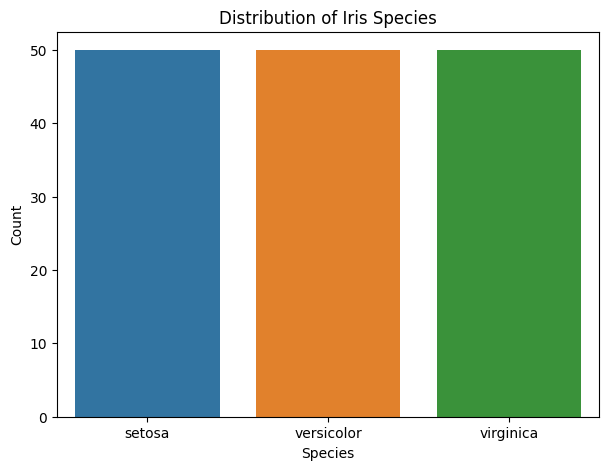

In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='species', hue='species', legend=False)

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()

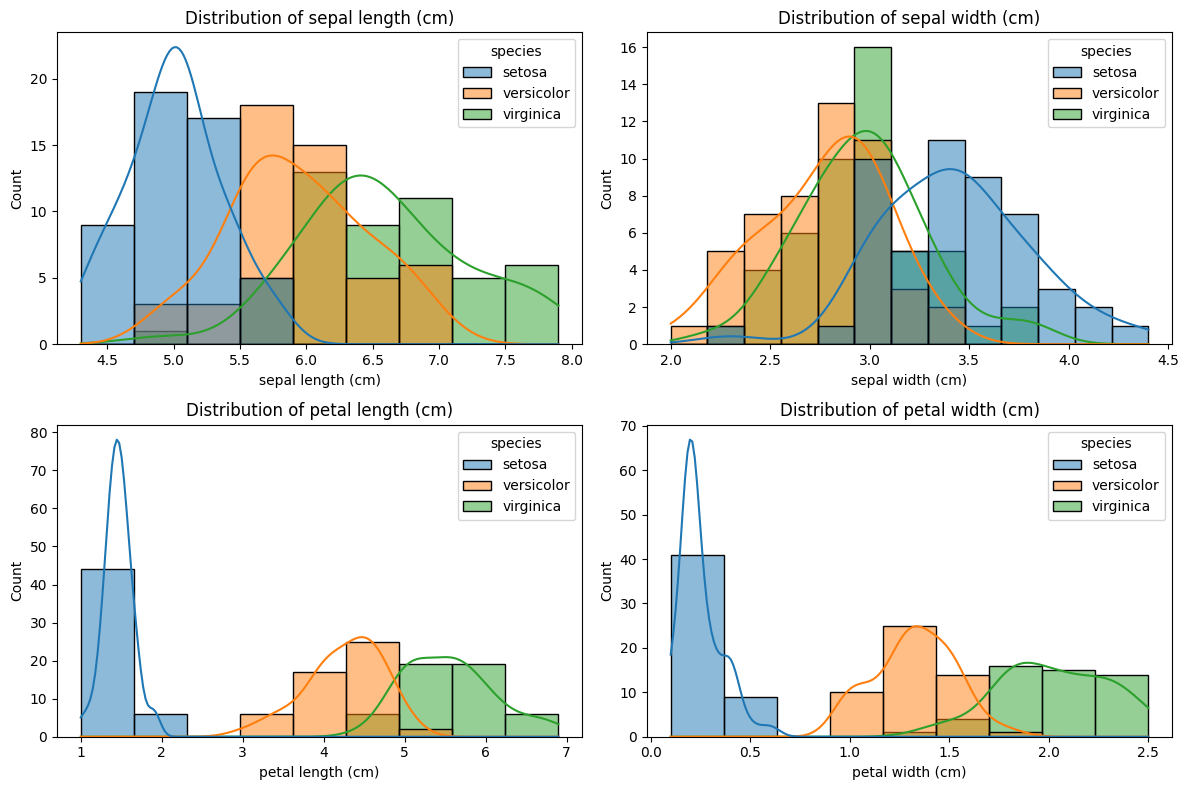

In [7]:
features = iris.feature_names

plt.figure(figsize=(12, 8))

for i, feature in enumerate(features):
    plt.subplot(2, 2, i + 1)
    sns.histplot(data=df, x=feature, hue='species', kde=True)
    plt.title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

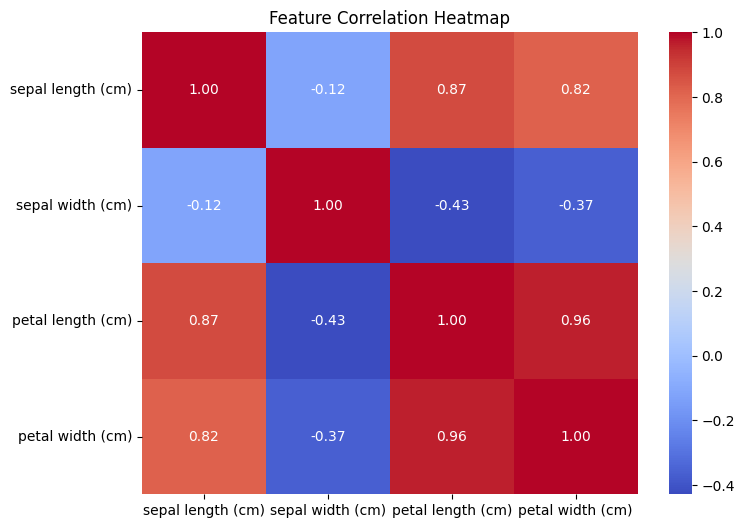

In [8]:
plt.figure(figsize=(8, 6))

correlation = df[features].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")
plt.show()

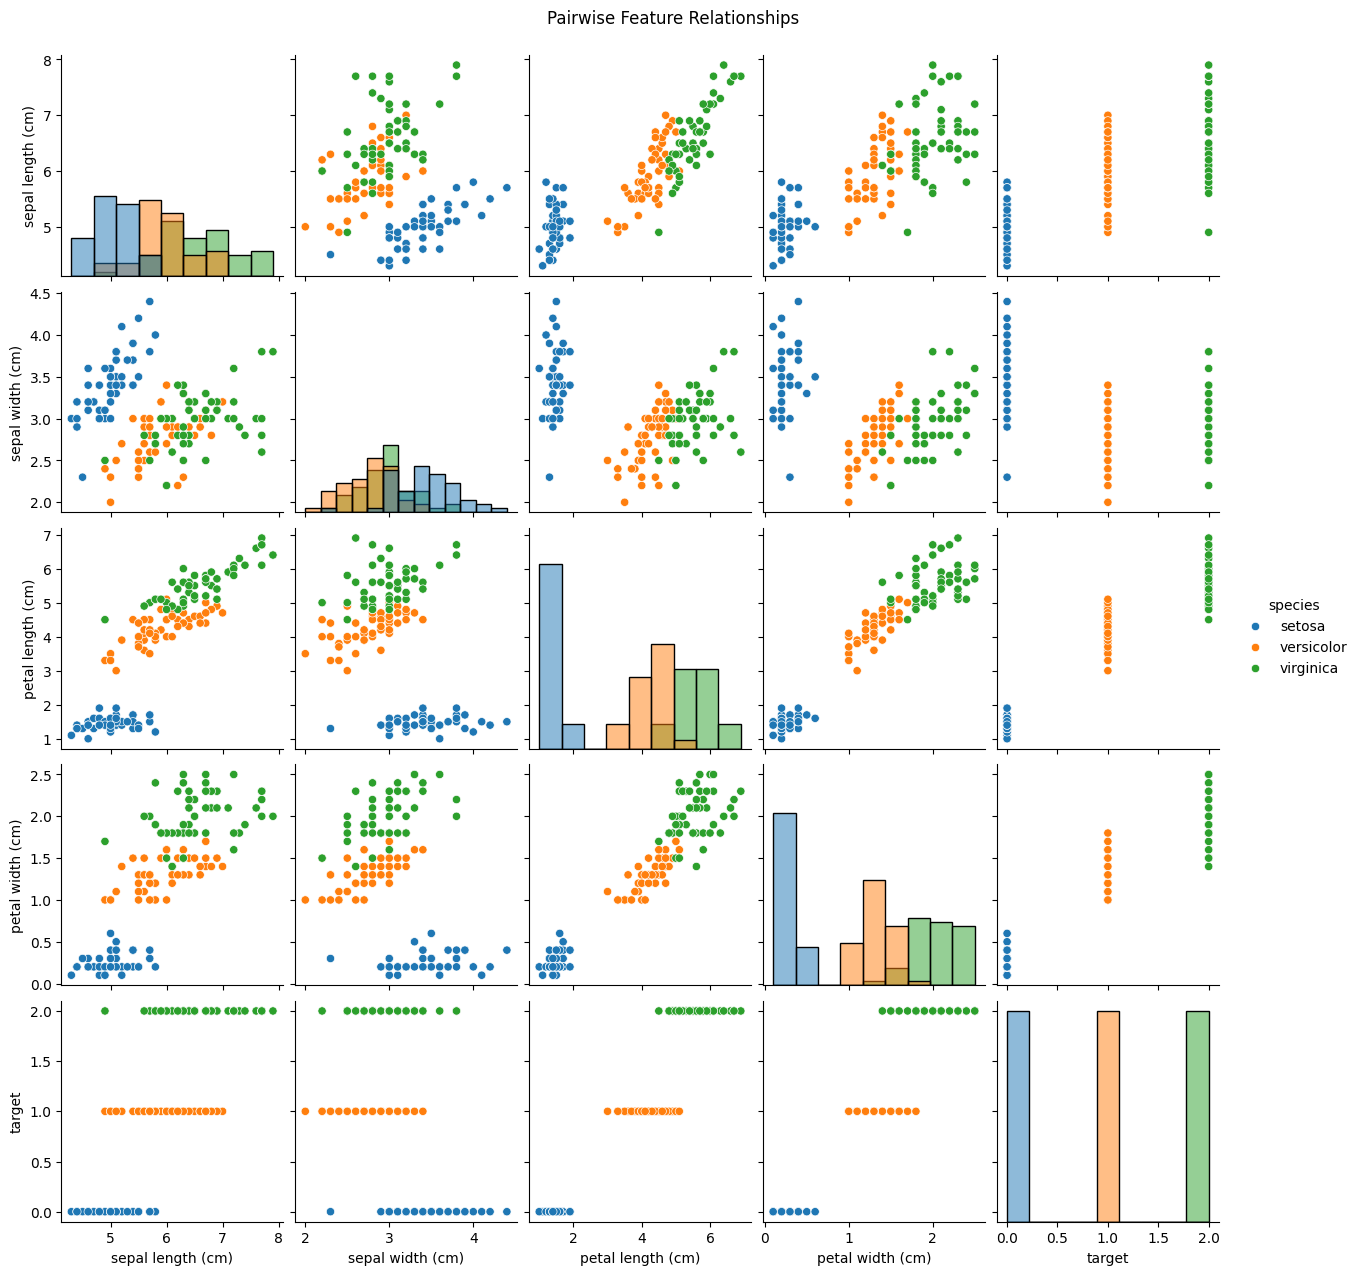

In [9]:
sns.pairplot(
    df,
    hue='species',
    diag_kind='hist'
)

plt.suptitle("Pairwise Feature Relationships", y=1.02)
plt.show()

In [10]:

X = df.drop(['target', 'species'], axis=1)

y = df['target']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (150, 4)
Target Shape: (150,)


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


In [12]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

log_model = LogisticRegression(
    max_iter=200,
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

y_pred_log = log_model.predict(X_test_scaled)

In [14]:
tree_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=42
)

tree_model.fit(X_train_scaled, y_train)

y_pred_tree = tree_model.predict(X_test_scaled)

In [15]:
from sklearn.metrics import accuracy_score

log_accuracy = accuracy_score(y_test, y_pred_log)

tree_accuracy = accuracy_score(y_test, y_pred_tree)

print("MODEL ACCURACY COMPARISON")
print("-" * 35)

print(f"Logistic Regression: {log_accuracy * 100:.2f}%")
print(f"Decision Tree:       {tree_accuracy * 100:.2f}%")

MODEL ACCURACY COMPARISON
-----------------------------------
Logistic Regression: 93.33%
Decision Tree:       96.67%


In [16]:
from sklearn.metrics import precision_score, recall_score, f1_score
log_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_log),
    'Precision': precision_score(y_test, y_pred_log, average='macro'),
    'Recall': recall_score(y_test, y_pred_log, average='macro'),
    'F1-Score': f1_score(y_test, y_pred_log, average='macro')
}

tree_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_tree),
    'Precision': precision_score(y_test, y_pred_tree, average='macro'),
    'Recall': recall_score(y_test, y_pred_tree, average='macro'),
    'F1-Score': f1_score(y_test, y_pred_tree, average='macro')
}

# Create comparison DataFrame
comparison_df = pd.DataFrame({
    'Logistic Regression': log_metrics,
    'Decision Tree': tree_metrics
})

print("CLASSIFICATION PERFORMANCE COMPARISON")
display(comparison_df.round(4))

CLASSIFICATION PERFORMANCE COMPARISON


,Logistic Regression,Decision Tree
Accuracy,0.9333,0.9667
Precision,0.9333,0.9697
Recall,0.9333,0.9667
F1-Score,0.9333,0.9666


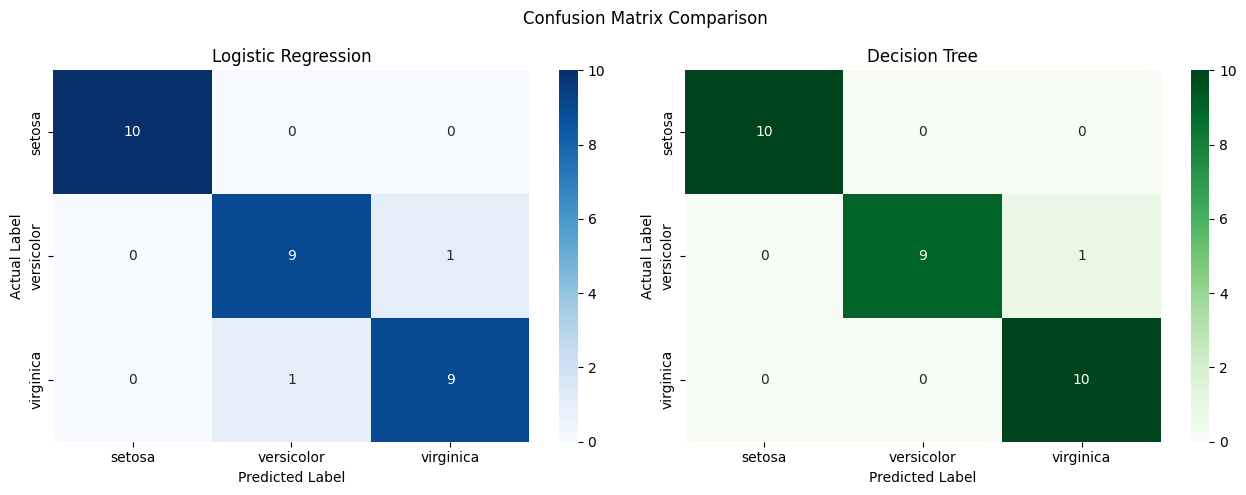

In [17]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_log = confusion_matrix(y_test, y_pred_log)

sns.heatmap(
    cm_log,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names,
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

# Decision Tree
cm_tree = confusion_matrix(y_test, y_pred_tree)

sns.heatmap(
    cm_tree,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names,
    ax=axes[1]
)

axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.suptitle("Confusion Matrix Comparison")
plt.tight_layout()
plt.show()

In [18]:
from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION REPORT")
print(classification_report(
    y_test,
    y_pred_log,
    target_names=iris.target_names
))

print("\nDECISION TREE REPORT")
print(classification_report(
    y_test,
    y_pred_tree,
    target_names=iris.target_names
))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


DECISION TREE REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [19]:
X_2d = df[['petal length (cm)', 'petal width (cm)']]
y_2d = df['target']

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_2d,
    test_size=0.20,
    random_state=42,
    stratify=y_2d
)
scaler_2d = StandardScaler()

X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)

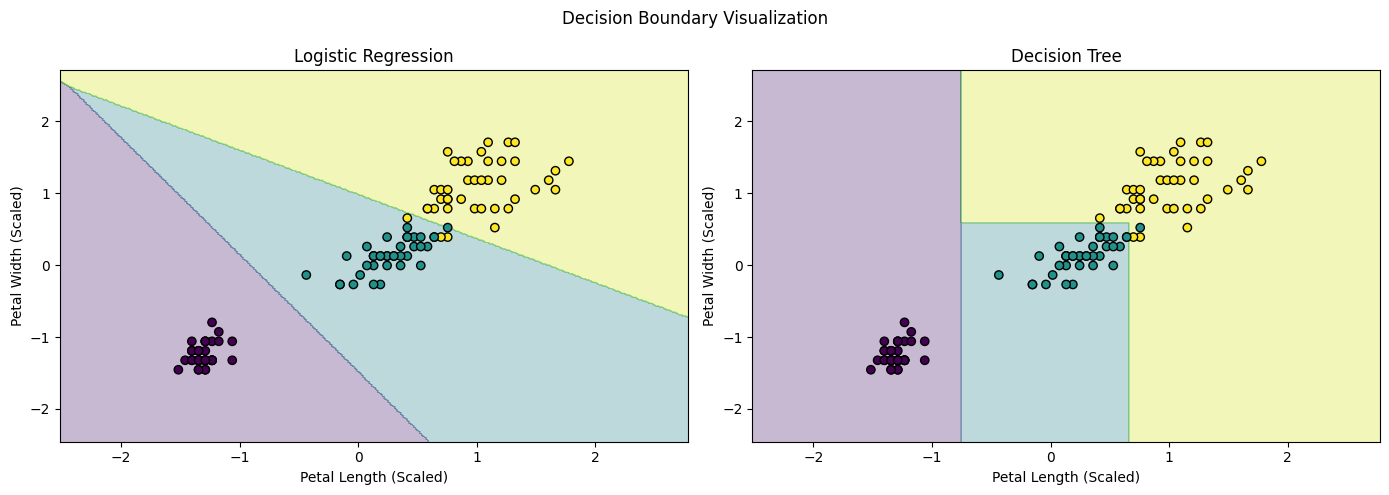

In [20]:
lr_2d = LogisticRegression(max_iter=200, random_state=42)
dt_2d = DecisionTreeClassifier(max_depth=3, random_state=42)

lr_2d.fit(X_train_2d_scaled, y_train_2d)
dt_2d.fit(X_train_2d_scaled, y_train_2d)

x_min, x_max = X_train_2d_scaled[:, 0].min() - 1, X_train_2d_scaled[:, 0].max() + 1
y_min, y_max = X_train_2d_scaled[:, 1].min() - 1, X_train_2d_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

Z_lr = lr_2d.predict(grid).reshape(xx.shape)
Z_dt = dt_2d.predict(grid).reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, Z, title in zip(
    axes,
    [Z_lr, Z_dt],
    ["Logistic Regression", "Decision Tree"]
):
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    ax.scatter(
        X_train_2d_scaled[:, 0],
        X_train_2d_scaled[:, 1],
        c=y_train_2d,
        cmap='viridis',
        edgecolors='black'
    )
    ax.set_title(title)
    ax.set_xlabel("Petal Length (Scaled)")
    ax.set_ylabel("Petal Width (Scaled)")

plt.suptitle("Decision Boundary Visualization")
plt.tight_layout()
plt.show()


# Final Conclusion

In this project, we developed a multi-class classification pipeline using the Iris dataset.

We performed exploratory data analysis, checked missing values, visualized feature distributions, and analyzed feature correlations.

The dataset was split into 80% training and 20% testing data. StandardScaler was applied to normalize the features.

Two supervised machine learning algorithms were implemented:
1. Logistic Regression
2. Decision Tree Classifier

Both models were evaluated using Accuracy, Precision, Recall, and F1-score.

The Decision Tree achieved 96.67% accuracy, while Logistic Regression achieved 93.33% accuracy on the test dataset.

Therefore, the Decision Tree performed better on this particular train-test split.

This project demonstrates the complete workflow of a supervised multi-class classification pipeline using Python and Scikit-Learn.
